# 03 · Transformation et statistiques (jalon M3)

**Objectif :** créer des variables temporelles, encoder les variables catégorielles, traiter les valeurs aberrantes, calculer des statistiques par tronçon (moyenne, médiane, écart-type, extrêmes, heures les plus chargées).

Entrée : `data/processed/comptages_propres.pkl` (issu de M2). Sorties : `data/processed/comptages_transformes.pkl` et `results/stats_par_troncon.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

df = pd.read_pickle("data/processed/comptages_propres.pkl")
print(df.shape)
df.head(3)

(102627, 9)


,iu_ac,axe,t_1h,q,k,etat_trafic,iu_nd_amont,iu_nd_aval,etat_barre
0,1029,Bd_Gal_Martial_Valin,2026-03-01 01:00:00+01:00,202.0,1.29500,Fluide,573,575,Ouvert
1,1029,Bd_Gal_Martial_Valin,2026-03-01 02:00:00+01:00,107.0,0.71222,Fluide,573,575,Ouvert
2,1029,Bd_Gal_Martial_Valin,2026-03-01 03:00:00+01:00,69.0,0.49222,Fluide,573,575,Ouvert


## 1. Variables temporelles
On extrait de `t_1h` ce qui explique le trafic : l'heure, le jour de la semaine, le week-end, le mois, les jours fériés. `t_1h` est déjà en heure de Paris : `.dt.hour` donne donc bien l'heure **locale** (pointe du matin vers 8 h, quel que soit l'été ou l'hiver).

In [2]:
JOURS = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
# Jours fériés français 2026 (dans la période mars-août)
FERIES = pd.to_datetime(["2026-04-06", "2026-05-01", "2026-05-08", "2026-05-14",
                         "2026-05-25", "2026-07-14", "2026-08-15"]).date

df["date"] = df["t_1h"].dt.date
df["heure"] = df["t_1h"].dt.hour
df["jour_semaine"] = df["t_1h"].dt.dayofweek            # 0 = lundi
df["nom_jour"] = pd.Categorical(df["jour_semaine"].map(dict(enumerate(JOURS))),
                                categories=JOURS, ordered=True)
df["mois"] = df["t_1h"].dt.month
df["semaine"] = df["t_1h"].dt.isocalendar().week.astype(int)
df["est_weekend"] = df["jour_semaine"] >= 5
df["est_ferie"] = df["date"].isin(FERIES)
df["type_jour"] = np.where(df["est_weekend"] | df["est_ferie"], "Week-end / férié", "Jour ouvré")
df["periode"] = pd.cut(df["heure"], bins=[-1, 5, 9, 15, 19, 23],
                       labels=["Nuit", "Pointe matin", "Journée", "Pointe soir", "Soirée"])
df[["t_1h", "heure", "nom_jour", "mois", "est_weekend", "est_ferie", "type_jour", "periode"]].sample(5, random_state=0)

,t_1h,heure,nom_jour,mois,est_weekend,est_ferie,type_jour,periode
63818,2026-08-27 15:00:00+02:00,15,Jeudi,8,False,False,Jour ouvré,Journée
58710,2026-07-19 09:00:00+02:00,9,Dimanche,7,True,False,Week-end / férié,Pointe matin
14069,2026-04-15 21:00:00+02:00,21,Mercredi,4,False,False,Jour ouvré,Soirée
57333,2026-05-22 14:00:00+02:00,14,Vendredi,5,False,False,Jour ouvré,Journée
12585,2026-08-13 13:00:00+02:00,13,Jeudi,8,False,False,Jour ouvré,Journée


In [3]:
print(df["type_jour"].value_counts())
print(df["periode"].value_counts().sort_index())

type_jour
Jour ouvré          69172
Week-end / férié    33455
Name: count, dtype: int64
periode
Nuit            25702
Pointe matin    17068
Journée         25531
Pointe soir     17145
Soirée          17181
Name: count, dtype: int64


**Pourquoi `type_jour` ?** Un lundi férié se comporte comme un dimanche. Si on se contentait de `est_weekend`, ces jours fériés pollueraient la courbe « jour ouvré ».

## 2. Encodage des variables catégorielles
Les algorithmes (statistiques, machine learning) travaillent avec des nombres. Le bon encodage dépend de la **nature** de la variable :

| Variable | Nature | Encodage |
|---|---|---|
| `etat_trafic` | **ordinale** (Fluide < Pré-saturé < Saturé < Bloqué) | entiers ordonnés 0 à 3 |
| `etat_barre`, `axe` | **nominale** (pas d'ordre) | *one-hot* (une colonne 0/1 par modalité) |
| `iu_ac`, `iu_nd_*` | **identifiants** | on ne les encode pas en nombres : ce ne sont pas des quantités |

Encoder `axe` en 0, 1, 2 serait une erreur : le modèle croirait que l'axe 2 est « deux fois » l'axe 1.

In [4]:
ORDRE_ETAT = {"Fluide": 0, "Pré-saturé": 1, "Saturé": 2, "Bloqué": 3}
df["etat_trafic_ord"] = df["etat_trafic"].astype("object").map(ORDRE_ETAT).astype("Int8")

onehot = pd.get_dummies(df[["axe", "etat_barre"]].astype("object"), prefix=["axe", "barre"], dtype=int)
df_enc = pd.concat([df, onehot], axis=1)
print(onehot.columns.tolist())
df_enc[["etat_trafic", "etat_trafic_ord"] + onehot.columns.tolist()].drop_duplicates().head(8)

['axe_Av_Ledru_Rollin', 'axe_Bd_Gal_Martial_Valin', 'axe_Bd_Richard_Lenoir', 'barre_Ouvert']


,etat_trafic,etat_trafic_ord,axe_Av_Ledru_Rollin,axe_Bd_Gal_Martial_Valin,axe_Bd_Richard_Lenoir,barre_Ouvert
0,Fluide,0,0,1,0,1
200,Saturé,2,0,1,0,1
417,Pré-saturé,1,0,1,0,1
537,Bloqué,3,0,1,0,1
5959,NaN,<NA>,0,1,0,1
26065,Fluide,0,0,0,1,1
27196,Pré-saturé,1,0,0,1,1
27197,Saturé,2,0,0,1,1


## 3. Valeurs aberrantes
Deux niveaux de contrôle :

1. **Valeurs impossibles** (règle métier) : `q` < 0, `k` < 0 ou `k` > 100 %. On les met à `NaN`.
2. **Valeurs statistiquement extrêmes** : règle de l'**écart interquartile** (IQR) **par tronçon**. Un tronçon à 1 000 véh/h et un tronçon à 100 véh/h n'ont pas le même « normal » : un seuil global serait injuste. Seuil retenu : au-dessus de Q3 + 3 × IQR (le facteur 3, plus large que le classique 1,5, évite de supprimer de vraies heures de pointe).

On garde les colonnes brutes `q`, `k` et on crée `q_net`, `k_net` : on ne détruit jamais l'information d'origine.

In [5]:
imp_q = (df["q"] < 0).sum()
imp_k = ((df["k"] < 0) | (df["k"] > 100)).sum()
print(f"Valeurs impossibles : q<0 = {imp_q}, k hors [0;100] = {imp_k}")

df["q_net"] = df["q"].where(df["q"] >= 0)
df["k_net"] = df["k"].where((df["k"] >= 0) & (df["k"] <= 100))

Valeurs impossibles : q<0 = 0, k hors [0;100] = 0


In [6]:
def borne_haute(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    return q3 + 3 * (q3 - q1)

for col in ["q_net", "k_net"]:
    seuil = df.groupby("iu_ac")[col].transform(borne_haute)
    df[f"{col}_aberrant"] = df[col] > seuil

print("q aberrants :", df["q_net_aberrant"].sum(), f"({df['q_net_aberrant'].mean():.3%})")
print("k aberrants :", df["k_net_aberrant"].sum(), f"({df['k_net_aberrant'].mean():.3%})")
df.loc[df["q_net_aberrant"], ["iu_ac", "t_1h", "q", "k"]].sort_values("q", ascending=False).head(8)

q aberrants : 3 (0.003%)
k aberrants : 3674 (3.580%)


,iu_ac,t_1h,q,k
5850,1030,2026-05-05 14:00:00+02:00,5478.95,1.86222
14538,1032,2026-05-05 14:00:00+02:00,5478.95,1.86222
23228,1034,2026-05-05 14:00:00+02:00,5478.95,8.46611


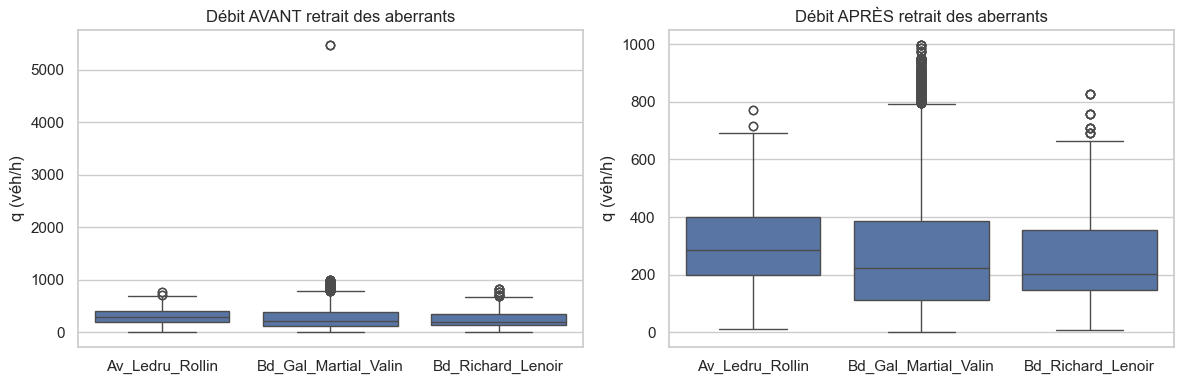

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="axe", y="q_net", ax=axes[0]); axes[0].set_title("Débit AVANT retrait des aberrants")
net = df.assign(q_ok=df["q_net"].mask(df["q_net_aberrant"]))
sns.boxplot(data=net, x="axe", y="q_ok", ax=axes[1]); axes[1].set_title("Débit APRÈS retrait des aberrants")
for a in axes: a.set(xlabel="", ylabel="q (véh/h)")
plt.tight_layout(); plt.show()

In [8]:
print("Max de q avant :", df["q_net"].max(), "| après :", net["q_ok"].max())
print("Médiane avant / après :", df["q_net"].median(), "/", net["q_ok"].median())

Max de q avant : 5478.95 | après : 998.0
Médiane avant / après : 236.0 / 236.0


**Comment lire :** si le maximum chute fortement alors que la médiane ne bouge pas, les aberrants étaient des erreurs de capteur isolées. Une médiane stable, c'est la preuve que le nettoyage ne déforme pas l'ensemble des données.

**Choix :** les valeurs aberrantes passent à `NaN` (on n'invente pas de remplacement), les analyses utilisent `q_net` et `k_net`.

In [9]:
for col in ["q_net", "k_net"]:
    df[col] = df[col].mask(df[f"{col}_aberrant"])
print(df[["q_net", "k_net"]].describe().round(1))

          q_net    k_net
count  101989.0  98888.0
mean      271.6      3.1
std       159.0      4.4
min         0.0      0.0
25%       154.0      0.8
50%       236.0      2.0
75%       384.0      3.7
max       998.0     63.1


## 4. Statistiques par tronçon
Pour chaque tronçon : moyenne, médiane, écart-type, minimum, maximum du débit, et occupation moyenne. **Moyenne vs médiane** : une moyenne bien supérieure à la médiane indique une distribution étirée vers les fortes valeurs ; l'**écart-type** mesure la variabilité (un tronçon très variable a des pointes marquées).

In [10]:
stats = (df.groupby(["axe", "iu_ac"], observed=True)
           .agg(q_moyen=("q_net", "mean"), q_median=("q_net", "median"), q_std=("q_net", "std"),
                q_min=("q_net", "min"), q_max=("q_net", "max"),
                k_moyen=("k_net", "mean"), k_max=("k_net", "max"),
                n_mesures=("q_net", "count"))
           .round(1))
stats.head(10)

q_moyen  q_median  q_std  q_min  q_max  k_moyen  \
axe                  iu_ac                                                    
Av_Ledru_Rollin      4663     321.6     339.0  121.0   20.0  616.0      4.2   
                     4664     209.1     224.0   77.9   10.0  410.0      4.8   
                     4669     321.6     339.0  121.0   20.0  616.0      2.8   
                     4670     209.1     224.0   77.9   10.0  410.0      3.8   
                     470      399.0     429.0  139.1   11.0  772.0     11.5   
                     471      399.0     429.0  139.1   11.0  772.0      6.9   
                     6305     209.2     224.0   77.9   10.0  410.0      3.8   
                     6306     321.6     339.0  121.0   20.0  616.0      2.7   
Bd_Gal_Martial_Valin 1029     320.9     243.5  236.0   19.0  998.0      2.1   
                     1030     227.7     210.0  143.0    0.0  977.0      1.2   

                            k_max  n_mesures  
axe                  iu_ac                    
Av_Ledru_Rollin      4663    16.3       4223  
                     4664    21.0       4331  
                     4669    10.4       4223  
                     4670    25.1       4331  
                     470     63.1       4309  
                     471     27.4       4309  
                     6305    25.2       4328  
                     6306    10.1       4223  
Bd_Gal_Martial_Valin 1029    12.2       4342  
                     1030     5.8       4342

### Heures les plus chargées
On calcule le débit moyen pour chaque couple (tronçon, heure), puis on retient les 3 heures les plus chargées de chaque tronçon.

In [11]:
profil = df.groupby(["iu_ac", "heure"], observed=True)["q_net"].mean()
top3 = profil.groupby(level=0).apply(lambda s: sorted(s.nlargest(3).index.get_level_values(1).tolist()))
stats = stats.reset_index().merge(top3.rename("heures_de_pointe"), left_on="iu_ac", right_index=True)
stats = stats.set_index(["axe", "iu_ac"])
stats[["q_moyen", "q_median", "q_std", "q_max", "heures_de_pointe"]].head(10)

q_moyen  q_median  q_std  q_max heures_de_pointe
axe                  iu_ac                                                  
Av_Ledru_Rollin      4663     321.6     339.0  121.0  616.0     [18, 19, 20]
                     4664     209.1     224.0   77.9  410.0     [16, 19, 20]
                     4669     321.6     339.0  121.0  616.0     [18, 19, 20]
                     4670     209.1     224.0   77.9  410.0     [16, 19, 20]
                     470      399.0     429.0  139.1  772.0      [0, 19, 23]
                     471      399.0     429.0  139.1  772.0      [0, 19, 23]
                     6305     209.2     224.0   77.9  410.0     [16, 19, 20]
                     6306     321.6     339.0  121.0  616.0     [18, 19, 20]
Bd_Gal_Martial_Valin 1029     320.9     243.5  236.0  998.0      [9, 18, 19]
                     1030     227.7     210.0  143.0  977.0      [9, 10, 19]

In [12]:
par_axe = stats.groupby("axe", observed=True).agg(
    nb_troncons=("q_moyen", "size"), q_moyen=("q_moyen", "mean"),
    q_std_moyen=("q_std", "mean"), k_moyen=("k_moyen", "mean")).round(1)
print(par_axe)
plus_charge = stats["q_moyen"].idxmax()
plus_calme = stats["q_moyen"].idxmin()
print(f"Tronçon le plus chargé : {plus_charge[1]} ({plus_charge[0]}), {stats.loc[plus_charge, 'q_moyen']:.0f} véh/h")
print(f"Tronçon le plus calme  : {plus_calme[1]} ({plus_calme[0]}), {stats.loc[plus_calme, 'q_moyen']:.0f} véh/h")
print("Heures de pointe les plus fréquentes :",
      pd.Series(sum(stats["heures_de_pointe"], [])).value_counts().head(5).to_dict())

                      nb_troncons  q_moyen  q_std_moyen  k_moyen
axe                                                             
Av_Ledru_Rollin                 8    298.8        109.4      5.1
Bd_Gal_Martial_Valin            6    274.3        189.5      2.0
Bd_Richard_Lenoir              10    247.8        101.5      2.1
Tronçon le plus chargé : 470 (Av_Ledru_Rollin), 399 véh/h
Tronçon le plus calme  : 1315 (Bd_Richard_Lenoir), 156 véh/h
Heures de pointe les plus fréquentes : {19: 19, 18: 11, 20: 11, 16: 8, 9: 6}


> ✍️ **À écrire dans vos propres mots :** quel axe est le plus chargé ? Les tronçons d'un même axe se ressemblent-ils (écart entre `q_moyen` min et max) ? À quelles heures la pointe tombe-t-elle ?

## 5. Sauvegarde

In [13]:
Path("results").mkdir(exist_ok=True)
stats.to_csv("results/stats_par_troncon.csv", encoding="utf-8-sig")
df_enc = pd.concat([df, onehot], axis=1)
df_enc.to_pickle("data/processed/comptages_transformes.pkl")
print(df_enc.shape)
print("Colonnes :", df_enc.columns.tolist())

(102627, 28)
Colonnes : ['iu_ac', 'axe', 't_1h', 'q', 'k', 'etat_trafic', 'iu_nd_amont', 'iu_nd_aval', 'etat_barre', 'date', 'heure', 'jour_semaine', 'nom_jour', 'mois', 'semaine', 'est_weekend', 'est_ferie', 'type_jour', 'periode', 'etat_trafic_ord', 'q_net', 'k_net', 'q_net_aberrant', 'k_net_aberrant', 'axe_Av_Ledru_Rollin', 'axe_Bd_Gal_Martial_Valin', 'axe_Bd_Richard_Lenoir', 'barre_Ouvert']


### Bilan M3
- Variables créées : `heure`, `jour_semaine`, `nom_jour`, `mois`, `semaine`, `est_weekend`, `est_ferie`, `type_jour`, `periode`.
- Encodage : ordinal pour `etat_trafic`, one-hot pour `axe` et `etat_barre`, identifiants laissés en texte.
- Aberrants : règle métier (valeurs impossibles) puis Q3 + 3·IQR par tronçon ; colonnes d'origine conservées.
- Statistiques par tronçon dans `results/stats_par_troncon.csv`.